In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score
from scipy.spatial import procrustes

from cblearn import embedding
from cblearn import utils
from cblearn.datasets import noisy_triplet_response, make_all_triplets

from dimensionality_estimation import fit_embedding

# seeds every random step of this notebook: the global numpy generator (ground truth
# and response noise), set at the start of the example and of the simulation, and
# the SOE initialisation of every fit
SEED = 0

sns.set_context('notebook')

In [2]:
n_objects = 18

dim = 2
dim_embedding = 2
# ground truth dimension and asked dimension match, so here we assume that we have estimated the dimension reliably

noise = 0.1

## Set ground truth

In [3]:
np.random.seed(SEED)

# ground truth
# 18 points randomly taking from a 2D Gaussian
X_true = np.random.normal(0, 1, (n_objects, dim))

# 18 points uniform random
#X_true = np.random.uniform(size=(n_objects, dim))
X_true 

array([[ 1.76405235,  0.40015721],
       [ 0.97873798,  2.2408932 ],
       [ 1.86755799, -0.97727788],
       [ 0.95008842, -0.15135721],
       [-0.10321885,  0.4105985 ],
       [ 0.14404357,  1.45427351],
       [ 0.76103773,  0.12167502],
       [ 0.44386323,  0.33367433],
       [ 1.49407907, -0.20515826],
       [ 0.3130677 , -0.85409574],
       [-2.55298982,  0.6536186 ],
       [ 0.8644362 , -0.74216502],
       [ 2.26975462, -1.45436567],
       [ 0.04575852, -0.18718385],
       [ 1.53277921,  1.46935877],
       [ 0.15494743,  0.37816252],
       [-0.88778575, -1.98079647],
       [-0.34791215,  0.15634897]])

## Sampling of triplets as in actual experiment

In [4]:
#all_triplets = make_all_triplets(X_true, result_format='list-order', monotonic = False)
#n_triplets = len(all_triplets)
#print(f"total number of triplets = {n_triplets}")

In [5]:
#all_triplets

In [6]:
#rng = np.random.default_rng(15122022)
#rng.shuffle(all_triplets, axis=0)

# from the total number we take 600 at random
#triplets_sample = all_triplets[:600, :].copy() # take first 600 triplets from shuffled 
#triplets_sample

In [7]:
# triplets were repeated 3 times
#triplets_sample = np.repeat(triplets_sample, 3, axis=0)

In [8]:
# here we simulate the error in the design
#triplets_sample2 = triplets_sample[:, [1, 0, 2]].copy()

In [9]:
#triplets_sample[:10, :]

In [10]:
#triplets_sample2[:10, :]

In [11]:
# we readout the triplets from the wrong calculated design files
df1 = pd.read_csv('../experiment/conditions/triplets_3x18_session1a.csv')
df2 = pd.read_csv('../experiment/conditions/triplets_3x18_session2a.csv')
design_df = pd.concat([df1,df2])

design_df = design_df[design_df['image_set']=='action']
design_df = design_df[['image1_index', 'middle_index', 'image2_index']]

In [12]:
design_df.groupby('middle_index').count()

,image1_index,image2_index
middle_index,,
0,63,63
1,64,64
2,62,62
3,42,42
4,57,57
5,44,44
6,44,44
7,40,40
8,44,44


In [13]:
design_df.head()

,image1_index,middle_index,image2_index
2,8,11,17
4,5,0,9
8,6,9,16
9,6,3,11
10,15,5,9


In [14]:
# as it was intended, the image1 was the reference (first column in 'list-order' format)
triplets_sample = design_df[['image1_index', 'middle_index', 'image2_index']].values
triplets_sample

array([[ 8, 11, 17],
       [ 5,  0,  9],
       [ 6,  9, 16],
       ...,
       [13,  9, 10],
       [10,  1,  3],
       [ 4, 12, 16]])

In [15]:
# as it was, the middle was the reference (first column in 'list-order' format)
triplets_sample2 = design_df[['middle_index', 'image1_index', 'image2_index']].values
triplets_sample2

array([[11,  8, 17],
       [ 0,  5,  9],
       [ 9,  6, 16],
       ...,
       [ 9, 13, 10],
       [ 1, 10,  3],
       [12,  4, 16]])

## Simulate triplet responses

In [16]:
for u in range(0, n_objects):
    ncount = np.sum(triplets_sample[:, 0]==u)
    ncount2 = np.sum(triplets_sample2[:, 0]==u)
    print(f"for object {u}: {ncount} / {ncount2} / diff: {ncount2 - ncount}")

for object 0: 28 / 63 / diff: 35
for object 1: 32 / 64 / diff: 32
for object 2: 27 / 62 / diff: 35
for object 3: 43 / 42 / diff: -1
for object 4: 36 / 57 / diff: 21
for object 5: 37 / 44 / diff: 7
for object 6: 30 / 44 / diff: 14
for object 7: 34 / 40 / diff: 6
for object 8: 36 / 44 / diff: 8
for object 9: 34 / 30 / diff: -4
for object 10: 32 / 34 / diff: 2
for object 11: 30 / 22 / diff: -8
for object 12: 39 / 16 / diff: -23
for object 13: 28 / 17 / diff: -11
for object 14: 33 / 13 / diff: -20
for object 15: 43 / 6 / diff: -37
for object 16: 34 / 2 / diff: -32
for object 17: 24 / 0 / diff: -24


In [17]:
triplets = noisy_triplet_response(triplets=triplets_sample, embedding = X_true,
                                   noise='normal', noise_options={'scale': noise}, result_format='list-order')

In [18]:
triplets2 = noisy_triplet_response(triplets=triplets_sample2, embedding = X_true,
                                   noise='normal', noise_options={'scale': noise}, result_format='list-order')

## Estimate embeddings

In [19]:
def estimate_and_align(triplets, dim_embedding, debug=True):
    # Estimate embedding random sampling
    X_est = fit_embedding(triplets, dim_embedding, random_state=SEED)
    assert(X_est.shape[1]==dim)

    #print(f"""
    #Train Accuracy = {soe.score(triplets):.2f}
    #Test  Accuracy = {soe.score(triplets_test):.2f}
    #CV    Accuracy = {cross_val_score(soe, triplets, cv=10).mean():.2f}""")

    # Procrustes: align, scale and rotation
    X_true_st, X_est, _ = procrustes(X_true, X_est)

    # RMSE
    rmse = np.sqrt(np.sum((X_true_st - X_est)**2)/n_objects)

    # Calculate SD of distances as measure of variability
    distances = np.sqrt(np.sum((X_true_st - X_est)**2, axis=1))

    std = np.std(distances)

    dist_range = np.ptp(distances) # range : max - min

    if debug:
        print(f"RMSE = {rmse:.2f} / STD distances = {std:.2f} / Range distances = {dist_range:.2f}")

    return X_true_st, X_est, rmse, std, dist_range

In [20]:
X_true_st, X_est, rmse, std, dist_range = estimate_and_align(triplets, dim_embedding)

X_true_st2, X_est2, rmse2, std2, dist_range2 = estimate_and_align(triplets2, dim_embedding)

np.testing.assert_almost_equal(X_true_st, X_true_st2)

RMSE = 0.02 / STD distances = 0.01 / Range distances = 0.05


RMSE = 0.03 / STD distances = 0.02 / Range distances = 0.07


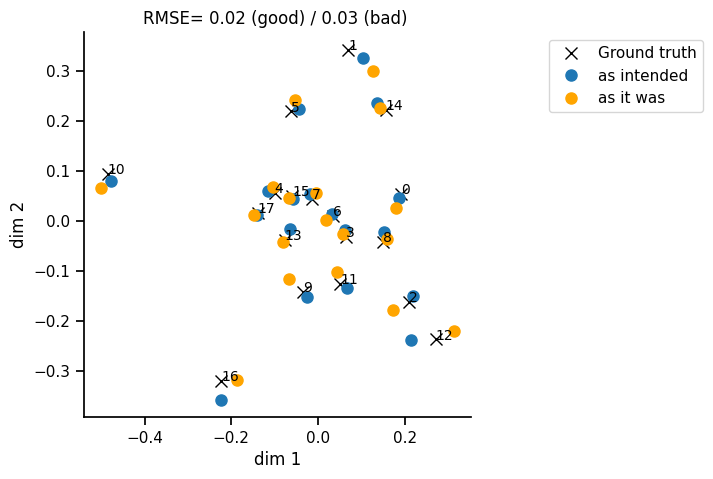

In [21]:
# Visualize
fig, ax = plt.subplots(1,1, figsize=(5, 5))
ax.plot(X_true_st[:, 0], X_true_st[:, 1], 'x', color='black', label='Ground truth', ms=8)
ax.plot(X_est[:, 0], X_est[:, 1], 'o', label='as intended', ms=8)
ax.plot(X_est2[:, 0], X_est2[:, 1], 'o', color='orange', label='as it was', ms=8)


for i in range(n_objects):
    ax.annotate(str(i), X_true_st[i,:], xycoords='data', fontsize=10)
    
ax.set_xlabel('dim 1')
ax.set_ylabel('dim 2')
ax.legend(loc='upper center', bbox_to_anchor=(1.4, 1.0))
ax.set_title(f"RMSE= {rmse:.2f} (good) / {rmse2:.2f} (bad) ")
sns.despine()

# Repeat simulation now 1000 times

In [22]:
N_simulations = 100
noises = np.arange(0.0, 0.5, 0.025).round(3)

In [23]:
len(noises)

20

In [24]:
np.random.seed(SEED)

data = []
for dist_gt in ['uniform', 'gaussian']:
    for noise in noises:
        print(f"noise: {noise}")
        
        for n in range(N_simulations):
            
            ## Set ground truth
            if dist_gt == 'gaussian':
                # 18 points randomly taking from a 2D Gaussian
                X_true = np.random.normal(0, 1, (n_objects, dim))
            elif dist_gt == 'uniform':
                # 18 points uniform random
                X_true = np.random.uniform(size=(n_objects, dim))
        
            # triplet_sample and triplet_sample2 as above, read from the actual experimental design file
            ## Simulate triplet responses
            triplets = noisy_triplet_response(triplets=triplets_sample, embedding = X_true,
                                               noise='normal', noise_options={'scale': noise}, result_format='list-order')
            triplets2 = noisy_triplet_response(triplets=triplets_sample2, embedding = X_true,
                                               noise='normal', noise_options={'scale': noise}, result_format='list-order')
            
            ## Estimate embeddings
            X_true_st, X_est, rmse, std, dist_range = estimate_and_align(triplets, dim_embedding, debug=False)
            X_true_st2, X_est2, rmse2, std2, dist_range2 = estimate_and_align(triplets2, dim_embedding, debug=False)
            
            np.testing.assert_almost_equal(X_true_st, X_true_st2)

            data.append([n, dist_gt, noise, 'as intended', 'RMSE', rmse])
            data.append([n, dist_gt, noise, 'as it was',  'RMSE', rmse2])

            data.append([n, dist_gt, noise, 'as intended', 'SD', std])
            data.append([n, dist_gt, noise, 'as it was',  'SD', std2])

            data.append([n, dist_gt, noise, 'as intended', 'range', dist_range])
            data.append([n, dist_gt, noise, 'as it was',  'range', dist_range2])
            

noise: 0.0


noise: 0.025


noise: 0.05


noise: 0.075


noise: 0.1


...

noise: 0.375


noise: 0.4


noise: 0.425


noise: 0.45


noise: 0.475


In [25]:
df = pd.DataFrame(data, columns=['nsim', 'distribution-gt', 'noise', 'sampling_design', 'metric', 'value'])
df.to_csv(f"../data/simul_design_error.csv")

In [26]:
# loading pre-computed simulation results
df = pd.read_csv(f"../data/simul_design_error.csv")

In [27]:
df_pivoted = df.pivot(columns='metric', index=['distribution-gt', 'noise', 'sampling_design', 'nsim'], values='value').reset_index()
df_pivoted

metric,distribution-gt,noise,sampling_design,nsim,RMSE,SD,range
0,gaussian,0.000,as intended,0,0.038950,0.026637,0.124514
1,gaussian,0.000,as intended,1,0.019971,0.009448,0.031913
2,gaussian,0.000,as intended,2,0.030592,0.018499,0.076937
3,gaussian,0.000,as intended,3,0.036572,0.023818,0.109715
4,gaussian,0.000,as intended,4,0.030285,0.012956,0.045528
...,...,...,...,...,...,...,...
7995,uniform,0.475,as it was,95,0.055602,0.022335,0.078150
7996,uniform,0.475,as it was,96,0.074532,0.043942,0.199218
7997,uniform,0.475,as it was,97,0.104234,0.058950,0.246295
7998,uniform,0.475,as it was,98,0.127651,0.071272,0.312749


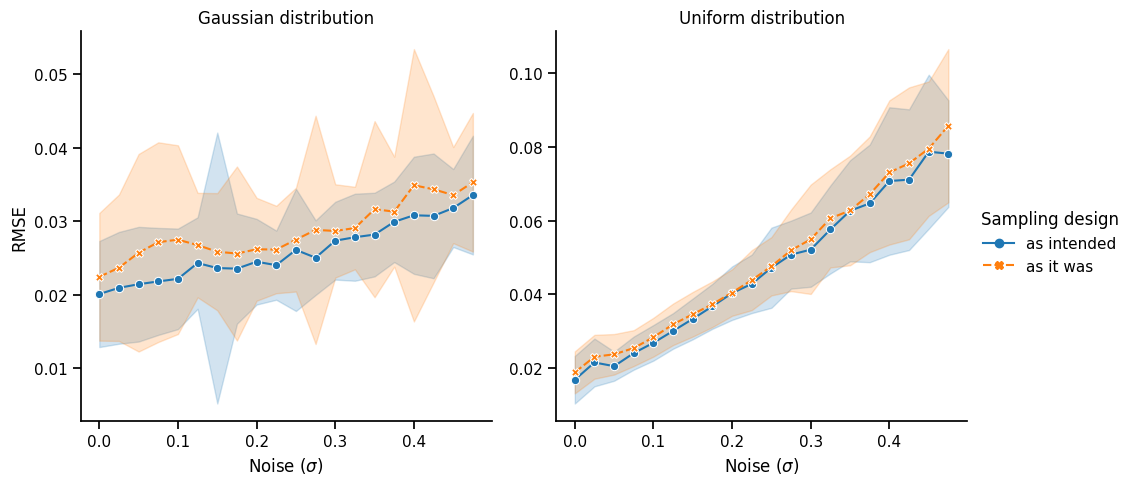

In [28]:
g = sns.relplot(data=df_pivoted, x='noise', y='RMSE', col='distribution-gt', hue='sampling_design', 
            kind='line',  style='sampling_design',
            markers=True, err_style='band', errorbar='sd', facet_kws={'sharey': False})
sns.despine()
g.set_xlabels(r'Noise ($\sigma$)')
for dist_gt, ax in g.axes_dict.items():
    ax.set_title(f"{dist_gt.capitalize()} distribution")
g.legend.set_title('Sampling design')
g.savefig('../plots/simul_design_error_RMSE.pdf')

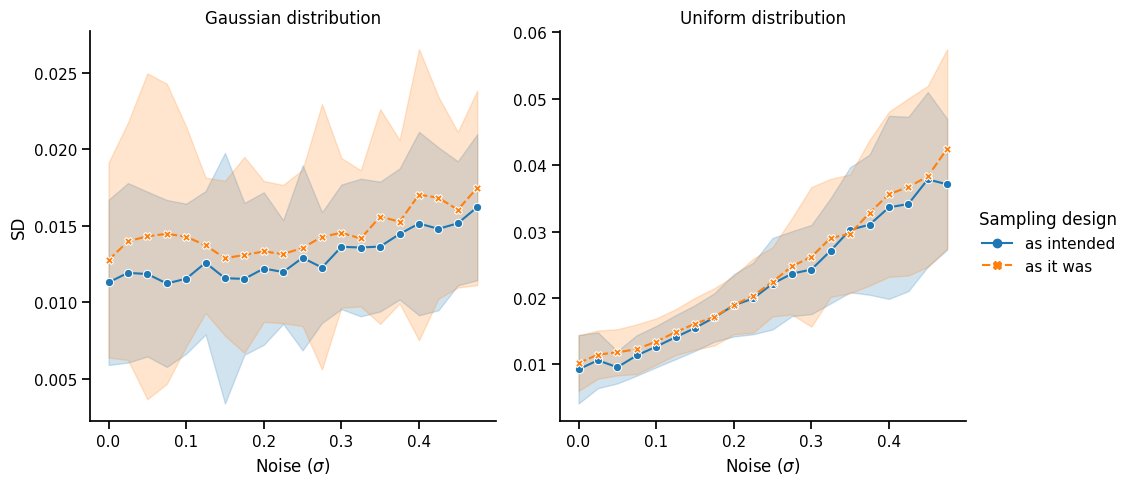

In [29]:
g = sns.relplot(data=df_pivoted, x='noise', y='SD', col='distribution-gt', hue='sampling_design', 
            kind='line',  style='sampling_design',
            markers=True, err_style='band', errorbar='sd', facet_kws={'sharey': False})
sns.despine()
g.set_xlabels(r'Noise ($\sigma$)')
for dist_gt, ax in g.axes_dict.items():
    ax.set_title(f"{dist_gt.capitalize()} distribution")
g.legend.set_title('Sampling design')
g.savefig('../plots/simul_design_error_SD.pdf')

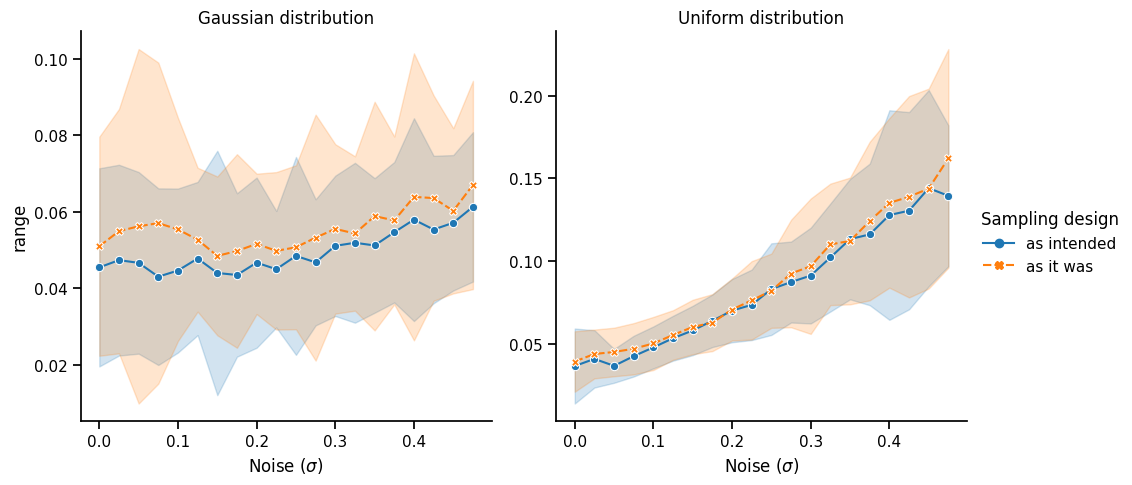

In [30]:
g = sns.relplot(data=df_pivoted, x='noise', y='range', col='distribution-gt', hue='sampling_design', 
            kind='line',  style='sampling_design',
            markers=True, err_style='band', errorbar='sd', facet_kws={'sharey': False})
sns.despine()
g.set_xlabels(r'Noise ($\sigma$)')
for dist_gt, ax in g.axes_dict.items():
    ax.set_title(f"{dist_gt.capitalize()} distribution")
g.legend.set_title('Sampling design')
g.savefig('../plots/simul_design_error_range.pdf')